# Phase 6 – Visualisation and presentation (Hungarian)

This notebook builds the two deliverables of Phase 6 and shows how they hang together:

- **the deck** (`prezentacio/WRFT_2023_elemzes.pdf`): about 15 main slides for the 10–12 minute talk, then a detailed appendix;
- **the interactive website** (`prezentacio/index.html`), which links to the deck and works offline.

Both are in Hungarian. All text lives in `src/flyball/report/text_hu.toml`; every number in it is a placeholder resolved from `reports/phase5/key_numbers.json` or the report tables, so the slides can't drift from the analysis. The same steps run from the command line: `uv run python scripts/run_phase6_presentation.py`.

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import SVG, display

from flyball import config
from flyball.plots import deck as deck_plots
from flyball.report import deck, figdata, numbers, site

warnings.simplefilter("ignore")
pd.set_option("display.max_colwidth", 90)
OUT = config.ROOT / "prezentacio"

---
## 1. Numbers: one registry, Hungarian formatting

`numbers.render()` replaces `{key|modifiers}` placeholders. Modifiers choose the form: `pp` percentage points, `ci` adds the 95 % CI (`KI`), `sign` forces a sign, `d0`–`d3` set decimals. Hungarian style: decimal comma, `40,8%`, `4,28 mp`, true minus sign. An unknown key raises an error (a test checks the whole text file).

In [2]:
examples = ["{wrft_win_rate}", "{wrft_median_run_s}", "{impact_all_reorders|ci}", "{day2_clean_heat_wrft|pp|ci}",
            "{lane_field_s|sign|ci}", "{lineup_orders_searched}", "{dog.maggie.starts}", "{a_team}"]
pd.DataFrame({"placeholder": examples, "printed": [numbers.render(e) for e in examples],
              "source": [numbers.get(e.strip("{}").split("|")[0])["source"] for e in examples]})

,placeholder,printed,source
0,{wrft_win_rate},"40,8%",reports/phase3/team_summary.csv
1,{wrft_median_run_s},"4,28 mp",reports/phase3/team_summary.csv
2,{impact_all_reorders|ci},+27 (20–33),reports/phase5/impact_ledger.csv
3,{day2_clean_heat_wrft|pp|ci},"+16,0 százalékpont (9,5–22,5)",reports/phase4b/weather_controls.csv
4,{lane_field_s|sign|ci},"+0,006 mp (0,003–0,010)",reports/phase4a/lane_run_effect.csv
5,{lineup_orders_searched},2 686 320,reports/phase4b/lineup_meta.csv
6,{dog.maggie.starts},14,reports/dog_scorecards.csv (starts)
7,{a_team},Maggie › Enola › Pax › Alfie,reports/phase4b/lineup_top.csv


---
## 2. The slides

The text file holds every slide in order, with its layout, the chart it shows, its bullets and the speaker notes. `part` separates the talk from the appendix.

In [3]:
text = deck.load_text()
pd.DataFrame([{"no": i, "part": s["part"], "layout": s["layout"], "time": s.get("time", ""), "title": s["title"]}
              for i, s in enumerate(text["slide"], start=1)])

,no,part,layout,time,title
0,1,main,cover,0:15,Gyorsak vagyunk. A futamokat a hibák miatt veszítjük el.
1,2,main,summary,1:00,"Kutyáink ugyanolyan gyorsak, mint a többieké – a futamokat a hibák miatt veszítjük el...."
2,3,main,chart,0:45,"20 versenynap, 1 116 futam, 7 °C és 34 °C között"
3,4,main,chart,0:45,"Hibátlan futammal 85% eséllyel nyerünk, ha az ellenfél hibázik; ha mi hibázunk, csak 9..."
4,5,main,chart,0:30,"Hanácké, a szezon első versenye: a Hopefuls több mint két másodperccel gyorsabb volt, ..."
5,6,main,chart,0:45,Minden javaslatot ugyanazzal mérünk: hány futammal nyernénk többet egy szezonban?
6,7,main,lineup_cards,1:00,"Négy csapatnál már a sorrend átrendezése kb. 27 plusz győzelmet hoz – ingyen, a követk..."
7,8,main,chart_side,1:00,Ugyanazok a csapatok vasárnap 16 százalékponttal több hibátlan futamot futnak – ha a s...
8,9,main,chart_side,1:15,"Minden csapatnak van egy jellemző, edzéssel javítható hibája: az XXL-nek a rajt, a Zep..."
9,10,main,ateam,0:45,"A legjobb csapat alapja Enola, Alfie és Maggie, negyediknek Pax illik melléjük – kis „..."


---
## 3. Charts

`plots/deck.py` draws every chart as an SVG with Hungarian labels, using the colour roles of `plots/style.py` (red/blue only for the lanes, violet = WRFT or the lever in focus, grey = field, aqua/orange = good/fault). Two examples: the season calendar and the impact ledger.

27 charts


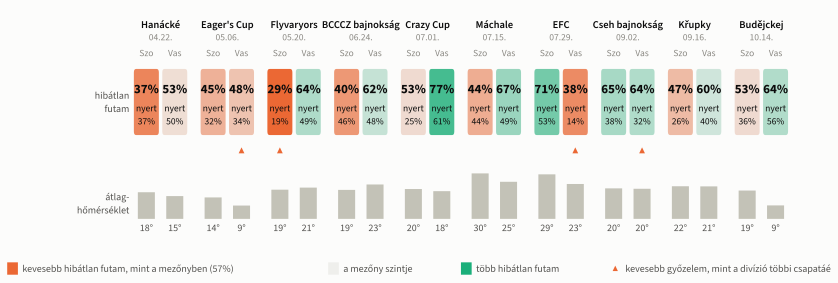

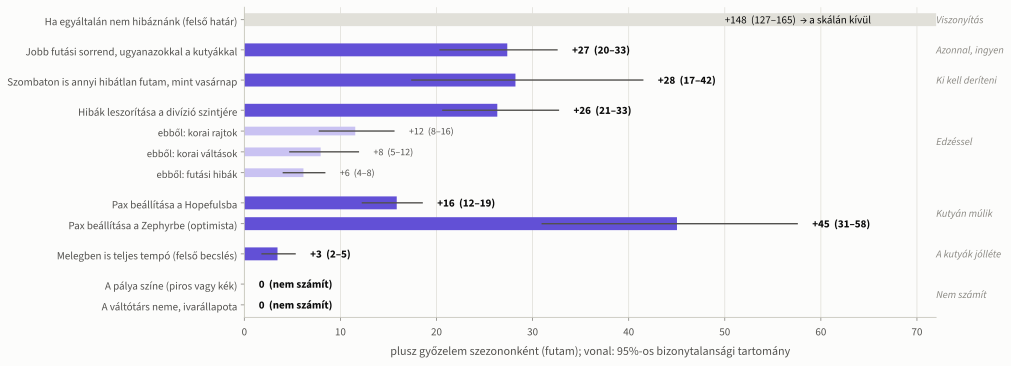

In [4]:
charts = deck_plots.build_all(figdata.chart_inputs())
print(len(charts), "charts")
display(SVG(filename=str(charts["season_calendar"])))
display(SVG(filename=str(charts["impact_ledger"])))

---
## 4. Deck and speaker notes (HTML → PDF)

The slides are Jinja2 templates (`report/templates/deck.html.j2`, `deck.css`) printed to PDF by headless Chromium (Playwright). PDF dates are blanked so rebuilds are byte-identical.

In [5]:
built = deck.build(OUT)
{k: str(v.relative_to(config.ROOT)) for k, v in built.items()}

{'html': 'reports/phase6/deck.html',
 'pdf': 'prezentacio/WRFT_2023_elemzes.pdf',
 'notes_pdf': 'prezentacio/WRFT_2023_eloadoi_jegyzet.pdf'}

---
## 5. Website and the line-up builder

`site.build()` writes `index.html`, `assets/` (styles, scripts, charts, fonts, the bundled Vega libraries and `data.js`) and `adatok/` (CSV downloads). The builder in the browser re-implements `lineup.score_orders` in `assets/lineup.js`; the exported arrays must reproduce the Phase 4B scores exactly. Here is the check in Python (the test suite also runs the JavaScript under Node).

In [6]:
prof = site.profiles()
web = site.build(OUT, prof=prof)
model = site.lineup_model(prof)

def score(names):            # the JavaScript formula, on the exported arrays
    by = {d["name"]: d for d in model["dogs"]}
    ds = [by[n] for n in names]
    h = min(d["h"] for d in ds)
    start = ds[0]["start"] if ds[0]["start"] is not None else ds[0]["start_any"]
    nf = ds[0]["fs"] + sum(d["ep"] for d in ds[1:]) + sum(d["rf"] for d in ds)
    return start + sum(d["run"][h][i] for i, d in enumerate(ds)) + sum(d["pass"] for d in ds[1:]) + model["fault_cost"] * nf

comp = pd.read_csv(config.REPORTS / "phase4b" / "lineup_comparison.csv")
comp["builder_s"] = [score(x.split(" > ")) for x in comp["line_up"]]
comp["diff"] = (comp["builder_s"] - comp["expected_s"]).abs()
print("largest difference:", round(comp["diff"].max(), 4), "s")
comp[["label", "expected_s", "builder_s"]].head(5)

largest difference: 0.0002 s


,label,expected_s,builder_s
0,A-team: Maggie > Enola > Pax > Alfie,19.2815,19.281443
1,Dreamers now: Maggie > Sirius > Alfie > Tyna,19.8331,19.832974
2,Dreamers reordered: Maggie > Tyna > Sirius > Alfie,19.8327,19.832624
3,Hopefuls now: Cookies > Enola > Maggie > Tyna,21.9852,21.985114
4,Hopefuls reordered: Maggie > Tyna > Cookies > Enola,19.7359,19.735737


---
## 6. The folder to upload

Everything the coach needs is in `prezentacio/`; `OLVASS_EL.md` explains (in Hungarian) how to open it and how to put it on GitHub Pages or Netlify.

In [7]:
files = sorted(p for p in OUT.rglob("*") if p.is_file())
sizes = pd.DataFrame({"part": [p.relative_to(OUT).parts[0] for p in files], "MB": [p.stat().st_size / 1e6 for p in files]})
sizes.groupby("part")["MB"].agg(["count", "sum"]).round(2)

,count,sum
part,,
OLVASS_EL.md,1,0.00
WRFT_2023_elemzes.pdf,1,0.88
WRFT_2023_eloadoi_jegyzet.pdf,1,0.04
adatok,4,0.02
assets,39,4.33
index.html,1,0.05
